# Phase 4b: SFT with Chain-of-Thought Scratchpad & Multi-Step (`arith_v3`)

Evaluates the latest **Chain-of-Thought Numeric Scratchpad + Multi-Step SFT** checkpoint (`e57bf52b...` `loud-grub-251`), inspecting step-by-step `Work:` reasoning traces across 3-digit `+ - * /`, PEMDAS, and conversational multi-step wordings (`multi_seq_word`, `multi_combine_word`, `multi_pemdas`).

- **Data Prep CLI:** `bash scripts/prepare_data.sh --format cot --multistep`
- **Training CLI:** `bash scripts/train.sh sft --preset sft_scratchpad`

In [1]:
from pathlib import Path
import sys

root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "main.py").is_file()), Path.cwd().parent)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.infra.eval_setup import setup_notebook_environment, configure_eval_device

project_root = setup_notebook_environment(root)
device, dtype = configure_eval_device("auto")  # 'auto', 'cuda', or 'cpu'

c:\Users\sampa\Dev\MiniReasoner\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root located at: C:\Users\sampa\Dev\MiniReasoner
ACTIVE EXECUTION DEVICE: CPU
CPU Threads:        4
Inference Dtype:    torch.float32
Mode:               Portable CPU Inference


## 1. Load Latest CoT SFT Checkpoint (`arith_format='scratchpad'`)

Discovered 8 run(s) in Azure container 'minireasoner':

Run ID                              Stage     Format      MLflow State  Snapshots  Last Updated (UTC)
--------------------------------------------------------------------------------------------------------
e57bf52bb95842dba6628092261584c4    sft       scratchpad  active        20         2026-11-26 05:56:23
ef3cc27cede44edf90ff5f205a2f71d6    sft       direct      active        16         2026-11-25 17:43:41
e8996fa3b67f48c8951cfd20f68ab40b    sft       direct      active        6          2026-11-25 17:17:13
23a72f3aa8d6487ca401b92b22ae229c    pretrain  -           active        53         2026-11-24 19:09:03
655ddf770790468d988bbb0375fd5aa4    pretrain  -           active        48         2026-11-24 09:22:26
6ef108a339da46679718b67143c39e2e    sft       scratchpad  deleted       4          2026-11-26 05:15:53
f9a6d03c46af4a378895622a82ace4c3    sft       direct      deleted       6          2026-11-25 17:12:04
c26cf6e5ffc749e6

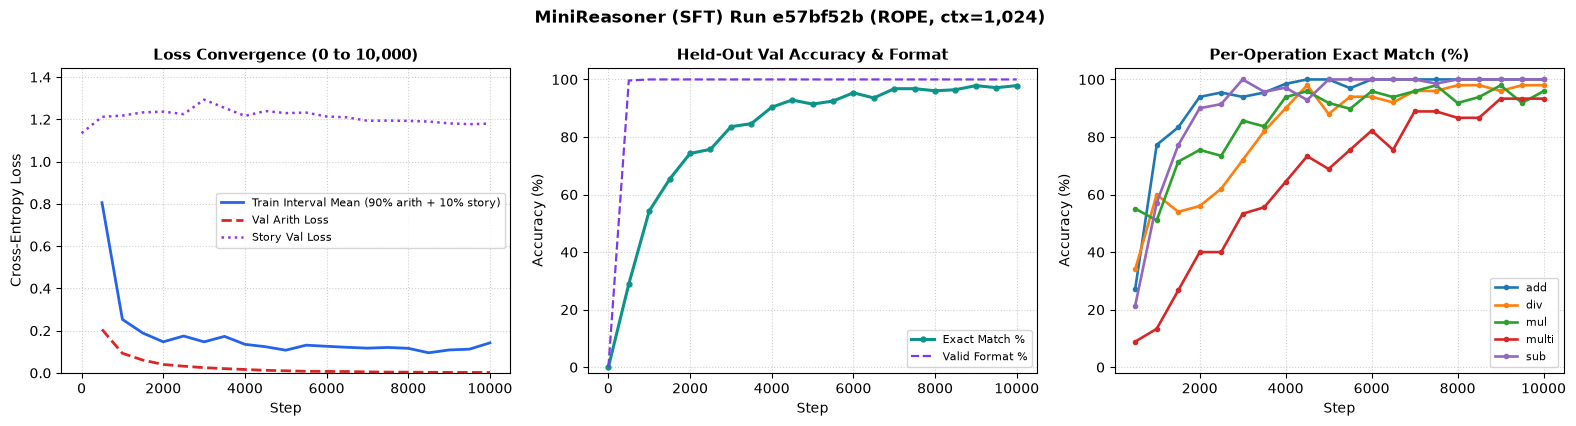

Initial Val Loss:        7.8871 (Step 0)
Latest Logged Val Loss:  0.0022 (Step 10,000)
Best Val Loss:           0.0022 (Step 10,000)
Peak Val Exact Match:    97.9% (Step 9,000)
Final Val Exact Match:   97.9% (Step 10,000)
Story Val Loss:          1.1341 (Step 0) -> 1.1796 (Step 10,000)


In [2]:
from src.infra.eval_setup import select_run_and_checkpoint, load_checkpoint_bundle, plot_run_history

RUN_ID = None                # Auto-selects newest active CoT/scratchpad SFT run (e.g. e57bf52b...)
CHECKPOINT_ALIAS = "latest"  # 'latest' (step 10,000), 'best', or 'step-N'
LOCAL_CHECKPOINT = None
COMPARE_WITH_BASE = False    # Set True to compare side-by-side with parent Base checkpoint

run_id, ckpt_path, snapshot = select_run_and_checkpoint(
    run_id=RUN_ID,
    checkpoint_alias=CHECKPOINT_ALIAS,
    local_checkpoint=LOCAL_CHECKPOINT,
    preferred_stages=("sft",),
    preferred_arith_format="scratchpad",
)
bundle = load_checkpoint_bundle(ckpt_path, device, dtype, snapshot=snapshot, compare_with_base=COMPARE_WITH_BASE)
model, tokenizer, model_config = bundle["model"], bundle["tokenizer"], bundle["model_config"]
arith_manifest = bundle["arith_manifest"]
plot_run_history(bundle["metrics_history"], run_id=run_id, model_config=model_config, stage=bundle["stage"], snapshot=snapshot)

## 2. Held-Out CoT Evaluation (`Work:` + `Answer:` Trace Inspection)

In [3]:
from src.core.benchmark import evaluate_arithmetic_split

# Uses standard sequential decoding (see phase4c_sft_kv_cache.ipynb for full 6,002-row KV-cached run)
EVAL_SPLIT = "val"
MAX_EXAMPLES = 30 if device.type == "cpu" else 280

eval_res = evaluate_arithmetic_split(
    model,
    tokenizer,
    model_config,
    arith_manifest,
    device=device,
    dtype=dtype,
    eval_split=EVAL_SPLIT,
    max_examples=MAX_EXAMPLES,
    batch_size=32,
    use_kv_cache=False,
    base_model=bundle["base_model"],
    base_tokenizer=bundle["base_tokenizer"],
)

PHASE 4 ARITHMETIC EVALUATION | split=val (30 rows) | format=scratchpad | multistep=True | kv_cache=False
Dataset:  C:\Users\sampa\Dev\MiniReasoner\data\sft\arithmetic\arith_v3_scratchpad_multistep_add-sub-mul-div_d3_signed_n12000_s42
Hardware: CPU | batch_size=32 | max_new_tokens=99
Computed masked val arith loss: 0.0006 (1,008 targets in 2.3s)
  Decoded 30/30 (100.0%) | 50.6s | 0.6 ex/s | ETA 0.0s

OVERALL VAL RESULTS (30 problems in 50.6s | 0.6 ex/s)
Exact Match Accuracy: 30/30 (100.00%)
Valid Format Rate:    30/30 (100.00%)
Masked Arith Loss:    0.0006

Per-Operation Breakdown:
  Op        Correct     Total     Accuracy
  ------------------------------------------
  add       7           7         100.00%
  div       6           6         100.00%
  mul       6           6         100.00%
  multi     5           5         100.00%
  sub       6           6         100.00%

Per-Category Breakdown:
  Category                Correct   Total     Accuracy
  -------------------------------

## 3. Wording Generalization & Story Retention Check

In [4]:
from src.core.benchmark import evaluate_wording_generalization, generate_timed

evaluate_wording_generalization(
    model,
    tokenizer,
    eval_res["examples"],
    device=device,
    answer_format="scratchpad",
    n_problems=10 if device.type == "cuda" else 4,
    max_new_tokens=eval_res["max_new_tokens"],
    use_kv_cache=False,
)

print("\nSimpleStories Retention Sanity Check:")
for sp in ("Once upon a time, there was a little", "Mia had a little dog named"):
    res = generate_timed(model, tokenizer, sp, max_new_tokens=60, temperature=0.0, use_cache=False, device=device)
    print(f"  {res['full_text'].strip()}")

WORDING GENERALIZATION (4 held-out problems, format=scratchpad)
  calculate                4/4   (100.0%)
  canonical                4/4   (100.0%)
  conversational_math      4/4   (100.0%)
  conversational_result    4/4   (100.0%)
  equation                 4/4   (100.0%)
  word_numbers             4/4   (100.0%)
  word_op                  4/4   (100.0%)

SimpleStories Retention Sanity Check:
  Once upon a time, there was a little girl named Mia. She loved to play in the snow. One day, she found a shiny stone. It sparkled like stars. Mia picked it up and felt a warm glow. Suddenly, she heard a voice. "That stone is special!" it said. Mia looked
  Mia had a little dog named Leo. Leo was not just any dog; he was a superhero with the power of invisibility. He could make anyone invisible! Mia thought, "If I use this power for good, I can help


## 4. CoT `Work:` Reasoning Trace Playground

In [5]:
from src.core.benchmark import create_ask_helper, create_math_chat_helpers

ask_math, _ = create_math_chat_helpers(model, tokenizer, device=device, answer_format="scratchpad", use_cache=False)
ask = create_ask_helper(model, tokenizer, device=device, answer_format="scratchpad", use_cache=False)

cot_probes = [
    ("What is -95 * 672?", -63840),
    ("What is 624 / 16?", 39),
    ("What is 8 + 8 * 3?", 32),
    ("If you compute 10 + 10 and also take 2 + 3, what is the sum of both results?", 25),
    ("Start with 100, subtract 35, and then multiply by 4. What is the final result?", 260),
]
for q, gold in cot_probes:
    ask_math(q, expected=gold)

Q: What is -95 * 672? [PASS]
   Work: 672*90=60480; 672*5=3360; 60480+3360=63840; neg=-63840
   Answer: -63840
   -> Extracted: -63840 (71 tok | 4031ms | 17.6 tok/s)
------------------------------------------------------------------------------
Q: What is 624 / 16? [PASS]
   Work: 16*30=480; 624-480=144; 16*9=144; 30+9=39
   Answer: 39
   -> Extracted: 39 (56 tok | 2744ms | 20.4 tok/s)
------------------------------------------------------------------------------
Q: What is 8 + 8 * 3? [PASS]
   Work: 8*3=24; 24+8=32
   Answer: 32
   -> Extracted: 32 (30 tok | 1130ms | 26.6 tok/s)
------------------------------------------------------------------------------
Q: If you compute 10 + 10 and also take 2 + 3, what is the sum of both results? [PASS]
   Work: 10+10=20; 3+2=5; 20+5=25
   Answer: 25
   -> Extracted: 25 (39 tok | 2651ms | 14.7 tok/s)
------------------------------------------------------------------------------
Q: Start with 100, subtract 35, and then multiply by 4. What is the f

In [12]:
_ = ask("what could be 23 + 42?", expected=65)

Q: what could be 23 + 42? [PASS]
   Work: 42+20=62; 62+3=65
   Answer: 65
   -> Extracted: 65 (32 tok | 993ms | 32.2 tok/s)
------------------------------------------------------------------------------
